# G5.38 — Da carteira aos ângulos: experimento explicado célula por célula

**Versão de apresentação do G5.38 executado.** O modelo, a função objetivo, os dados, as cinco sementes, o protocolo de CVaR e os checkpoints continuam definidos como na execução original. Nesta versão, cada pequena célula de código tem uma explicação imediatamente acima.

**Pergunta científica:** uma rede produz os ângulos de um circuito parametrizado em **um único forward**; esses ângulos geram carteiras energeticamente melhores que a preparação de Dicke? E como elas se comparam ao 1-SWAP?

> **Resultados preservados:** as saídas históricas, tabelas e imagens de sua execução foram mantidas. Para apresentá-las hoje, **não é necessário selecionar “Executar tudo”** — isso repetiria 15 treinamentos caros. Ao executar do zero, os cálculos serão refeitos nos dados do seu computador, com a mesma configuração científica. A longa saída do treino foi recolhida, sem apagá-la.

## Mapa do método — do dado à solução

```text
Preços 2023–2026
      │ (janelas anteriores a cada data)
      ▼
Retorno esperado μ e covariância Σ ──► Hamiltoniano E(x)
      │                                    │
      ├── 32 carteiras de contexto ────────┘
      │         │
      ▼         ▼
Geometria de g gates + estatísticas financeiras
      │
      ▼
T_H: g linhas × 18 números
      │ normalização usando SOMENTE 2024
      ▼
Encoder Transformer: 18 → 48 características por gate
      │ atenção entre os g gates
      ▼
Δφ₁, …, Δφ_g (UM forward da rede)
      │ somamos os ângulos analíticos de Dicke
      ▼
Circuito: φ = φ_D + Δφ
      │ 96 shots por lado do SPSA, durante treinamento
      ▼
Bitstrings (sempre com k ativos) → energia → CVaR 10%
      │ diferença de recompensas + e −
      ▼
SPSA → direção de ajuste → MSE direcional → AdamW
      │
      ▼
Validação em 2024: selecionar checkpoint BEST
      │
      ▼
Teste em 2025/2026 com pesos CONGELADOS + ótimo clássico
```

**Três palavras que não devemos misturar:** *forward* = execução da rede; *shot* = uma medição do circuito; *atualização* = ajuste de pesos durante treinamento. Na inferência: **um forward, um vetor angular e vários shots**.

## Primeiro exemplo para a apresentação: 4C2

Imagine quatro ativos **A, B, C e D**, dos quais podemos escolher **exatamente dois**. Há apenas $\binom{4}{2}=6$ carteiras. O bitstring `1010` indica A e C; a posição de cada dígito representa um ativo na ordem A,B,C,D **apenas nesta ilustração**.

**O próximo código não treina nem simula nada:** ele simplesmente enumera as seis escolhas para que todo mundo compreenda a pergunta antes de falar de Transformer.

In [1]:
from itertools import combinations
ativos = 'ABCD'
for escolha in combinations(ativos, 2):
    bits = ''.join('1' if ativo in escolha else '0' for ativo in ativos)
    print(f'{bits} → {" + ".join(escolha)}')

1100 → A + B
1010 → A + C
1001 → A + D
0110 → B + C
0101 → B + D
0011 → C + D


## 1. Preparar bibliotecas

**Entrada:** nenhuma; apenas módulos Python e Qiskit instalados. **Código abaixo:** importa vetores, dados, PyTorch e simulador quântico. **Saída:** nomes das bibliotecas disponíveis, sem executar o treinamento.

In [2]:
from pathlib import Path
from functools import lru_cache
import hashlib, json, math, time, copy, os
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
try:
    from qiskit import QuantumCircuit
    from qiskit_aer import AerSimulator
except ImportError as exc:
    raise ImportError("Instale no Jupyter: %pip install qiskit qiskit-aer") from exc
from IPython.display import display

## 2. Fixar o experimento completo, sem modo piloto

**O que cada valor controla?** Cinco sementes repetem o treino independentemente. Para **cada** Hamiltoniano de treinamento, o SPSA usa 3 direções × 2 lados × 96 shots = **576 medições**. `RHO` limita a correção angular; `ANGLE_STEP` regula a direção-alvo transmitida ao AdamW. As constantes reproduzem o modo completo já executado.

In [3]:
SEEDS = (11, 23, 37, 41, 53)
SPSA_DIRECTIONS, SPSA_SHOTS = 3, 96
VAL_SHOTS, VAL_REPEATS = 128, 2
TEST_SHOTS, INPUT_SAMPLES = 128, 32
SPSA_C, ANGLE_STEP = 0.18, 0.06
LR, RHO = 3e-4, 1.2
DATA_SEED, MAX_UNIVERSES = 20261014, 3
FULL_POOL_PASSES, NUM_VALIDATION_CHECKS = 1, 8
VALIDATION_CASE_LIMIT = 20
TAU_EI = 0.20  # EI aparece somente em diagnósticos; NÃO na perda
ARMS = ('ENCODER_ONLY', 'ENCODER_ONLY_MATCHED', 'ENCODER_DECODER_CROSS')
POLICIES = ('BEST', 'LAST')
RUN_EXACT_DISTRIBUTION_SHOWCASE = True

## 3. Separar as topologias por papel científico

- **Treino:** todas as combinações de 2 a 12 qubits, exceto as quatro topologias reservadas.
- **Validação:** cinco topologias de 2024, sem atualização dos pesos.
- **Teste:** 9C4, 10C5, 11C5 e 12C5, com datas de 2025–2026.

A escrita `10C5` significa **10 ativos, escolher exatamente 5**, e não “dez portas quânticas”. Seu circuito usa $g=k(n-k)=25$ ângulos.

In [4]:
BASE_SPECS = ((10, 3), (10, 4), (10, 6), (12, 4), (12, 6))
HELDOUT_SPECS = ((9, 4), (10, 5), (11, 5), (12, 5))
MULTI_SPECS = tuple((n, k) for n in range(2, 13) for k in range(1, n)
                    if (n, k) not in HELDOUT_SPECS)
ALL_SPECS = tuple(sorted(set(MULTI_SPECS + HELDOUT_SPECS)))

## 4. Localizar os CSVs e a pasta dos resultados

**Entrada:** arquivos `prices_adjusted_2023_2026.csv` e `asset_manifest_g51.csv` no Desktop, ou diretório indicado nas variáveis de ambiente originais. **Saída:** pasta `g538_didatico_reexecucao_2024`, separada do experimento original. Assim, reexecutar a versão didática **não sobrescreve os checkpoints anteriores**.

In [5]:
DATA_DIR = Path(os.getenv('G537_DATA_DIR',
    os.getenv('G527_DATA_DIR', os.getenv('G523_DATA_DIR', str(Path.home()/'Desktop'))))).expanduser().resolve()
PRICES = DATA_DIR / 'prices_adjusted_2023_2026.csv'
MANIFEST = DATA_DIR / 'asset_manifest_g51.csv'
OUT = Path('g538_didatico_reexecucao_2024').resolve()
OUT.mkdir(exist_ok=True, parents=True)
BACKEND = AerSimulator(method='matrix_product_state', max_parallel_threads=2)
torch.set_num_threads(min(4, torch.get_num_threads()))

def stable_seed(key):
    return int(hashlib.sha256(str(key).encode()).hexdigest()[:8], 16)

for path in (PRICES, MANIFEST):
    if not path.is_file():
        raise FileNotFoundError(f'Arquivo ausente: {path}')
print('CSV de preços:', PRICES)
print('Saídas:', OUT)

CSV de preços: /home/marlonmaxuel/Desktop/prices_adjusted_2023_2026.csv
Saídas: /home/marlonmaxuel/Desktop/g538_didatico_reexecucao_2024


## 5. Definir as datas e janelas históricas

Cada data é uma fotografia do problema. A janela de 60, 75, 90 ou 120 pregões usa **somente preços anteriores à data da fotografia**; os testes futuros não entram nas estatísticas financeiras do treino.

**Exemplo:** em 2024-04-30 com janela de 60 pregões, calculamos $\mu$ e $\Sigma$ apenas com os 60 retornos anteriores, e não com preços de 2025.

In [6]:
ANCHORS={
 'train_old':['2024-04-30','2024-05-31','2024-06-28','2024-07-31'],
 'train_extended':['2024-01-31','2024-02-15','2024-02-29','2024-03-15','2024-03-28','2024-04-15','2024-04-30','2024-05-15','2024-05-31','2024-06-14','2024-06-28','2024-07-15','2024-07-31'],
 'val':['2024-08-30','2024-09-30'],
 'test25':['2025-03-31','2025-06-30','2025-09-30','2025-12-30'],
 'test26':['2026-03-31','2026-06-30','2026-09-30'],
}
WINDOWS=(60,75,90,120)

## 6. Ler e conferir os dados financeiros

**Entrada:** manifesto (tickers e rótulos `train`, `val`, `calib`, `holdout`) e preços. **O código abaixo** exige colunas correspondentes, preços positivos e cobertura até setembro/2026. **Saída:** `RET`, a tabela de retornos diários $r_t=P_t/P_{t-1}-1$.

In [7]:
manifest=pd.read_csv(MANIFEST,dtype=str)
assert {'ticker','split'}.issubset(manifest.columns)
assert not manifest.ticker.duplicated().any()
prices=pd.read_csv(PRICES,index_col=0,parse_dates=True).sort_index()
prices.index=pd.DatetimeIndex(prices.index).tz_localize(None)
assert not prices.index.has_duplicates
missing=sorted(set(manifest.ticker)-set(prices.columns))
if missing:raise ValueError(f'Faltam preços para {missing[:15]}')
if prices.index.max()<pd.Timestamp('2026-09-30'):
    raise ValueError('Base de preços termina antes de setembro/2026.')
prices=prices.loc[:,manifest.ticker.tolist()].astype(float)
if (prices.le(0)&prices.notna()).any().any():raise ValueError('Preços não positivos.')
RET=prices.pct_change(fill_method=None).replace([np.inf,-np.inf],np.nan)
GROUPS={s:sorted(manifest.loc[manifest.split==s,'ticker'].tolist())
        for s in ('train','val','calib','holdout')}
if any(len(v)<12 for v in GROUPS.values()):
    raise ValueError('Cada grupo precisa de 12 ativos distintos no manifesto.')

## 7. Criar universos independentes de ativos

Os tickers são separados pelo manifesto. Para cada grupo, embaralhamos com semente fixa e dividimos em universos de 12 ativos. **A mesma lista de ativos pode gerar topologias diferentes (10C3, 10C4, etc.)**, por isso as observações não são independentes.

In [8]:
UNIVERSES={}
for group,tickers in GROUPS.items():
    rng=np.random.default_rng(stable_seed(f'{DATA_SEED}|{group}|12'))
    arr=np.asarray(tickers,dtype=object);rng.shuffle(arr)
    UNIVERSES[group]=[tuple(arr[i*12:(i+1)*12]) for i in range(min(len(arr)//12,MAX_UNIVERSES))]
assert all(UNIVERSES.values())

## 8. Selecionar os ativos que formarão cada Hamiltoniano

A função `assets_subset` mantém a escolha de ativos reprodutível para a mesma quantidade `n`, grupo e universo. Modificar `k` altera quantos ativos podem ser escolhidos, **não** a lista de ativos candidatos.

In [9]:
def assets_subset(universe,group,uid,n):
    # Mesmo universo/same n para diferentes k: testa mudança de cardinalidade.
    rng=np.random.default_rng(stable_seed(f'{DATA_SEED}|assets|{group}|{uid}|{n}'))
    perm=rng.permutation(len(universe))
    return tuple(universe[int(t)] for t in perm[:n])

## 9. Converter séries históricas em um problema de otimização

**Entrada:** grupo, data, janela, $n$ e $k$. Para cada ativo calculamos o retorno anualizado $\mu_i=252\bar r_i$. A covariância anualizada é $\Sigma_{ij}=252\operatorname{Cov}(r_i,r_j)$.

**Saída:** cada `r` contém o identificador da instância, a lista de ativos e o par `mu`/`Sigma`; ainda **não há resposta ótima**.

In [10]:
def make_instances(split,specs):
    groups={'train_old':['train'],'train_extended':['train'],'val':['val'],
            'test25':['train','holdout'],'test26':['train','holdout']}[split]
    rows=[];rejections=[]
    for group in groups:
        for uid,universe in enumerate(UNIVERSES[group]):
            for n,k in specs:
                assets=assets_subset(universe,group,uid,n)
                for date in ANCHORS[split]:
                    anchor=pd.Timestamp(date)
                    hist=RET.loc[:anchor,list(assets)].dropna(how='any')
                    if hist.empty or hist.index[-1].year!=anchor.year or (anchor-hist.index[-1]).days>10:
                        rejections.append((split,group,uid,n,k,date,'anchor'));continue
                    for w in WINDOWS:
                        if len(hist)<w:
                            rejections.append((split,group,uid,n,k,date,'window'));continue
                        frame=hist.tail(w)
                        mu=(252*frame.mean()).to_numpy(dtype=float)
                        cov=(252*frame.cov()).to_numpy(dtype=float)
                        cov=(cov+cov.T)*0.5
                        if not(np.isfinite(mu).all() and np.isfinite(cov).all()):
                            raise ValueError('Hamiltoniano não finito.')
                        ident=f'{split}|{group}|{uid}|{n}C{k}|{date}|{w}'
                        rows.append(dict(id=ident,split=split,group=group,universe=uid,
                                         date=date,window=w,n=n,k=k,spec=(n,k),assets=assets,
                                         mu=mu,Sigma=cov))
    return rows,rejections

## 10. Construir treino e validação de 2024

`BASE_40` e `BASE_70` são referências históricas para comparar diversidade; `MULTI_ALL` é o conjunto completo realmente usado no G5.38. As quatro topologias de teste ficam excluídas de `MULTI_ALL`.

In [11]:
BASE_40,rej40=make_instances('train_old',BASE_SPECS)
BASE_70,rej70=make_instances('train_extended',BASE_SPECS)
MULTI_ALL,rejmulti=make_instances('train_extended',MULTI_SPECS)
VAL,rejval=make_instances('val',BASE_SPECS)
assert BASE_40 and BASE_70 and MULTI_ALL and VAL
assert all(q['date'][:4]=='2024' for q in BASE_40+BASE_70+MULTI_ALL+VAL)
assert not any(q['spec'] in HELDOUT_SPECS for q in MULTI_ALL)

## 11. Construir o subconjunto multicardinal de comparação

Além do conjunto completo, geramos uma amostra com tamanho comparável ao conjunto BASE. Ela cobre primeiro as topologias e depois completa com outras instâncias. **Não é este subconjunto que alimenta o treinamento principal.**

In [12]:
def choose_multicardinal_matched(pool,qty):
    # Repartir cobertura por topologia (1 instância por nCk), e completar amostra.
    rng=np.random.default_rng(stable_seed('G527|multi_matched|2024'))
    by_spec={s:[r for r in pool if r['spec']==s] for s in MULTI_SPECS}
    chosen=[];used=set()
    for spec in MULTI_SPECS:
        if not by_spec[spec]:continue
        rr=by_spec[spec][int(rng.integers(len(by_spec[spec])))]
        chosen.append(rr);used.add(rr['id'])
    if len(chosen)>qty:
        # Quando houver mais specs do que exemplos, estratificar deterministicamente.
        picks=rng.choice(len(chosen),size=qty,replace=False)
        return [chosen[int(i)] for i in sorted(picks)]
    rest=[r for r in pool if r['id'] not in used]
    add=rng.choice(len(rest),size=min(qty-len(chosen),len(rest)),replace=False)
    chosen.extend(rest[int(i)] for i in add)
    return chosen

## 12. Conferir a diversidade disponível

**Saída esperada na execução fornecida:** `BASE_MULTI_ALL`: **9.672 instâncias, 62 topologias, 13 datas e 1.716 trios distintos (ativos, data, janela)**. Essas quantidades não devem ser chamadas de 9.672 observações financeiras independentes.

In [13]:
MULTI_70=choose_multicardinal_matched(MULTI_ALL,len(BASE_70))
assert len(MULTI_70)==len(BASE_70)
TRAIN_POOLS={'BASE_5_40':BASE_40,'BASE_5_70':BASE_70,
             'BASE_MULTI_70':MULTI_70,'BASE_MULTI_ALL':MULTI_ALL}
rows=[]
for arm,pool in TRAIN_POOLS.items():
    rows.append(dict(arm=arm,instances=len(pool),distinct_specs=len(set(r['spec'] for r in pool)),
                     distinct_dates=len(set(r['date'] for r in pool)),
                     distinct_hamiltonians=len(set((r['assets'],r['date'],r['window']) for r in pool))))
manifest_protocol=pd.DataFrame(rows)
manifest_protocol.to_csv(OUT/'training_pool_comparison.csv',index=False)
pd.DataFrame(rej40+rej70+rejmulti+rejval,
             columns=['split','group','universe','n','k','date','reason']).to_csv(OUT/'rejected_2024.csv',index=False)
print(manifest_protocol.to_string(index=False))

           arm  instances  distinct_specs  distinct_dates  distinct_hamiltonians
     BASE_5_40        240               5               4                     96
     BASE_5_70        780               5              13                    312
 BASE_MULTI_70        780              62              13                    597
BASE_MULTI_ALL       9672              62              13                   1716


## 13. Do problema binário ao circuito

Uma carteira é $x\in\{0,1\}^n$, com **exatamente** $k$ posições iguais a 1. Avaliamos

$$E_H(x)=\tfrac12 x^\top \Sigma x-\mu^\top x.$$

- $x$: quais ativos foram escolhidos;
- $\Sigma$: penalidade de risco, via covariância;
- $\mu$: recompensa de retorno esperado;
- **menor energia** = melhor carteira **sob essa função objetivo**.

O ansatz tem $g=k(n-k)$ gates parametrizados. Por exemplo, **4C2 usa 4 gates** e tem **6 carteiras válidas**; **10C5 usa 25 gates** e tem **252 carteiras**.

### 13.1 — Desenhar o conjunto de gates a partir de n e k

`active_gates` calcula o par de qubits `(i,l)`, se a operação é `CY` ou `CCY`, seu período e o ângulo inicial analítico de Dicke. Nenhuma rede é necessária para preparar esses ângulos iniciais.

In [14]:
def active_gates(n,k):
    gates=[]
    for l in range(n-1,-1,-1):
        for i in range(l-1,l-1-k,-1):
            if i<0 or (l>=n-k and i>=n-k): continue
            typ='CY' if i==l-1 else 'CCY'
            ang=(2 if typ=='CY' else 1)*np.arccos(np.sqrt((l-i)/(l+1)))
            period=4*np.pi if typ=='CY' else 2*np.pi
            gates.append(dict(i=i,l=l,gate=typ,period=period,phiD=2*np.pi*ang/period))
    assert len(gates)==k*(n-k),(n,k,len(gates))
    return gates

### 13.2 — Por que $\mathrm{CY}$ usa $4\pi$?

A rotação $R_y(\alpha)=e^{-i\alpha Y/2}$ satisfaz $R_y(\alpha+2\pi)=-R_y(\alpha)$. Em uma **rotação controlada**, esse sinal só afeta o ramo com controle ligado, podendo alterar a fase relativa. Por isso, a matriz controlada volta exatamente ao mesmo operador após **$4\pi$**, embora a probabilidade de um circuito particular possa ter simetrias adicionais.

No código usamos um ângulo adimensional $\phi$ em que o ângulo físico enviado à porta é $\alpha=\phi\,\text{período}/(2\pi)$. Isso preserva o tratamento distinto de `CY` e `CCY`.

### 13.3 — Implementar uma rotação CY com portas básicas

O simulador MPS aceita `RY` e `CX`. Assim, o código usa uma decomposição equivalente à rotação controlada, em vez de depender de `CRY` nativo. **Não estamos trocando a unitária do gate.**

In [15]:
def apply_controlled_ry(qc, control, target, angle):
    half = float(angle) / 2
    qc.ry(half, target)
    qc.cx(control, target)
    qc.ry(-half, target)
    qc.cx(control, target)

### 13.4 — Preparar e parametrizar o circuito

**Entrada:** topologia `(n,k)` e um vetor `phi` com `g` ângulos. **Passos:** inicializar os `k` qubits da preparação; aplicar a sequência de portas definidas; medir todos os qubits. Uma chamada monta **um circuito com um conjunto de ângulos**.

In [16]:
def build_parameterized_circuit(topology, phi):
    if len(phi) != topology.d:
        raise ValueError('Número incorreto de ângulos')
    qc = QuantumCircuit(topology.n)
    for i in range(topology.n):
        if (topology.initial >> i) & 1:
            qc.x(i)
    angles = np.asarray(phi) * topology.period / (2*np.pi)
    for angle, gate in zip(angles, topology.gates):
        i, l = gate['i'], gate['l']
        qc.cx(i,l)
        if gate['gate'] == 'CY':
            apply_controlled_ry(qc, l, i, angle)
        else:
            qc.ry(float(angle),i)
            qc.ccx(l,i+1,i)
            qc.ry(float(-angle),i)
            qc.ccx(l,i+1,i)
        qc.cx(i,l)
    qc.measure_all()
    assert set(qc.count_ops()).issubset({'x','ry','cx','ccx','measure','barrier'})
    return qc

### 13.5 — Fazer shots e converter para os bits dos ativos

O Aer devolve as cadeias na ordem `q[n−1]...q[0]`. O código as inverte para alinhá-las às colunas de `mu` e `Sigma`. **Cada linha de `X` é uma carteira medida**, podendo repetir uma já observada. Conferimos que toda carteira possui exatamente `k` ativos.

In [17]:
def measure_bitstrings(topology, phi, shots, seed):
    qc = build_parameterized_circuit(topology, phi)
    result = BACKEND.run(qc, shots=int(shots),
                         seed_simulator=int(seed), memory=True).result()
    if not result.success:
        raise RuntimeError(f'Falha no Aer: {result.status}')
    memory = result.get_memory(0)
    if len(memory) != shots:
        raise AssertionError('Quantidade incorreta de shots')
    bits = [str(s).replace(' ','') for s in memory]
    if any(len(s) != topology.n or set(s)-{'0','1'} for s in bits):
        raise AssertionError('Bitstrings inválidos')
    X = np.array([[int(v) for v in reversed(s)] for s in bits], dtype=np.int8)
    if not np.all(X.sum(axis=1) == topology.k):
        raise AssertionError('Circuito saiu da cardinalidade permitida')
    return X

### 13.6 — Organizar a topologia em um objeto pequeno

A classe abaixo somente reúne geometria de gates, ângulos iniciais, método de construir o circuito, medir e exibir o bitstring. Assim as etapas anteriores ficam visíveis e separadas.

In [18]:
class Topology:
    def __init__(self, n, k):
        self.n, self.k = n, k
        self.spec = f'{n}C{k}'
        self.gates = active_gates(n,k)
        self.d = len(self.gates)
        self.phiD = np.array([g['phiD'] for g in self.gates])
        self.period = np.array([g['period'] for g in self.gates])
        self.initial = sum(1 << (n-j-1) for j in range(k))

    def circuit(self, phi):
        return build_parameterized_circuit(self, phi)

    def measure(self, phi, shots, seed):
        return measure_bitstrings(self, phi, shots, seed)

    def label(self, x):
        return ''.join(map(str, np.asarray(x,dtype=int)[::-1]))

### 13.7 — Verificar se Dicke conserva a cardinalidade

**Autoteste real do circuito:** construir 2C1, 4C3, 10C4 e 12C5, medir 8 vezes em cada e confirmar que nenhuma medição seleciona número errado de ativos. A saída abaixo é a da sua execução anterior.

In [19]:
CIRCS={spec:Topology(*spec) for spec in ALL_SPECS}
for spec in ((2,1),(4,3),(10,4),(12,5)):
    c=CIRCS[spec]
    observed=c.measure(c.phiD,8,stable_seed(f'G527|selftest|{spec}'))
    assert observed.shape==(8,spec[0]) and np.all(observed.sum(axis=1)==spec[1])
print('Aer MPS: autotestes de cardinalidade aprovados.')

Aer MPS: autotestes de cardinalidade aprovados.


## 14. Como Monte Carlo entra **antes** do Transformer

Para cada Hamiltoniano sorteamos **32 carteiras válidas**, calculamos a energia de cada uma e resumimos três números: média, desvio e menor energia.

**Importante:** esses números não são o ótimo exato nem rótulos de $\theta$; são **informações de contexto**. A amostragem Monte Carlo do **treinamento SPSA** ocorrerá mais adiante e tem outro papel.

### 14.1 — Amostrar carteiras e calcular energias

`random_k` produz `count` vetores binários, cada um com exatamente `k` ativos. `energies_subset` aplica a mesma função $E_H(x)$ a todas as linhas de uma vez.

In [20]:
def random_k(n,k,rng,count):
    X=np.zeros((count,n),dtype=np.int8)
    for t in range(count):
        X[t,rng.choice(n,size=k,replace=False)]=1
    return X

def energies_subset(X,mu,Sigma):
    X=np.asarray(X,dtype=float)
    return 0.5*np.einsum('bi,ij,bj->b',X,Sigma,X)-X@mu

### 14.2 — Resumir as 32 carteiras de contexto

**Entrada:** uma instância `r`, com `mu` e `Sigma`. **Saída:** `r["context"]`, contendo as carteiras sorteadas, suas energias e os três resumos estatísticos. A semente depende somente do identificador da instância, garantindo comparações reprodutíveis.

In [21]:
def add_context(r):
    rng=np.random.default_rng(stable_seed(r['id']+'|context32'))
    X=random_k(r['n'],r['k'],rng,INPUT_SAMPLES)
    e=energies_subset(X,r['mu'],r['Sigma'])
    r['context']={'X':X,'energies':e,'mean':float(e.mean()),
                  'std':float(e.std()),'sample_min':float(e.min())}

## 15. Os 18 atributos de cada gate — a verdadeira entrada da rede

Cada gate vira **uma linha** com 18 números. Os dez primeiros identificam tamanho, posição, tipo e geometria; os cinco seguintes descrevem os ativos ligados à porta; os três últimos são as estatísticas das 32 carteiras.

| Colunas | Informação | Significado |
|---|---|---|
| 1–3 | $j/(g-1)$, $n/(n+12)$, $k/n$ | posição e escala global |
| 4–5 | $i/(n-1)$, $l/(n-1)$ | qubits da porta |
| 6–10 | CY/CCY, $\phi_D/\pi$, período e razão geométrica | geometria de Dicke |
| 11–15 | $\mu_i,\mu_l,\Sigma_{ii},\Sigma_{ll},\Sigma_{il}$ | contexto financeiro local |
| 16–18 | média, desvio, mínimo de 32 energias | contexto financeiro global |

**Exemplo:** em 2C1, a rede recebe `1 × 18`; em 10C5, `25 × 18`; em 12C6, `36 × 18`. São **18 atributos por gate**, e não 18 atributos para o problema inteiro.

### 15.1 — Construir a matriz dos tokens

O `for` percorre os gates e junta os 18 números de cada um. **Saída:** matriz de formato `(g,18)`. As colunas 2, 3 e 16–18 podem se repetir entre os gates porque descrevem o mesmo Hamiltoniano; as demais podem variar conforme os qubits e o gate.

In [22]:
def raw_tokens(r):
    n,k=r['n'],r['k'];c=CIRCS[(n,k)];mu=r['mu'];cov=r['Sigma']
    sd=np.diag(cov);s=r['context']
    rows=[]
    for j,g in enumerate(c.gates):
        i,l=g['i'],g['l']
        rows.append([j/max(c.d-1,1),n/(n+12),k/n,i/(n-1),l/(n-1),
                     float(g['gate']=='CY'),float(g['gate']=='CCY'),
                     g['phiD']/np.pi,g['period']/(4*np.pi),
                     np.sqrt((l-i)/(l+1)),   # geometria ANALÍTICA local: sem J completa
                     mu[i],mu[l],sd[i],sd[l],cov[i,l],
                     s['mean'],s['std'],s['sample_min']])
    return np.asarray(rows,dtype=np.float32)

### 15.2 — Ajustar a escala dos 18 atributos sem consultar o futuro

A padronização usa **somente o conjunto financeiro de treino (2024)**:

$$z_{j,a}=\operatorname{clip}\!\left(\frac{T_{j,a}-\bar T_a}{s_a},-10,10\right).$$

`clip` limita valores extremos do atributo padronizado a `−10` ou `+10`. Isso evita entradas muito grandes; **não** é uma probabilidade. Média e desvio são reaproveitados sem reajuste nos testes de 2025–2026.

In [23]:
# O mesmo Hamiltoniano pode aparecer em pools diferentes; não duplica no scaler.
for pool in TRAIN_POOLS.values():
    for r in pool:
        if 'context' not in r:
            add_context(r)
for r in VAL:
    add_context(r)
ALL_TRAIN_BY_ID = {r['id']:r for pool in TRAIN_POOLS.values() for r in pool}
ALL_TRAIN = list(ALL_TRAIN_BY_ID.values())
RAW = np.concatenate([raw_tokens(r) for r in ALL_TRAIN], axis=0)
MEAN = RAW.mean(axis=0)
STD = np.maximum(RAW.std(axis=0), 1e-5)
assert RAW.shape[1] == 18
np.savez(OUT/'scaler_train_2024_only.npz', mean=MEAN, std=STD)

### 15.3 — Transformar os tokens em tensores PyTorch

Subtraímos a média, dividimos pelo desvio, aplicamos `clip` e criamos um tensor `float32`. **É esse tensor que o Transformer recebe.** As dimensões impressas foram conservadas da execução original.

In [24]:
def token_tensor(r):
    scaled = (raw_tokens(r)-MEAN)/STD
    return torch.from_numpy(np.clip(scaled,-10,10).astype(np.float32))

print('Exemplo 2C1:', raw_tokens(next(r for r in MULTI_ALL if r['spec']==(2,1))).shape)
print('Exemplo 12C6:', raw_tokens(next(r for r in MULTI_ALL if r['spec']==(12,6))).shape)

Exemplo 2C1: (1, 18)
Exemplo 12C6: (36, 18)


## 16. O Transformer: como 18 números viram um ângulo por gate

A camada inicial é $\text{Linear}(18,48)$: cada token com **18 atributos** torna-se um vetor de **48 componentes aprendidas**. Em seguida, duas camadas de encoder e quatro cabeças de atenção permitem que os gates influenciem uns aos outros.

A saída tem **um escalar por token**: $\Delta\phi_j=\rho\tanh(w^\top z_j+b)$.

- $z_j\in\mathbb{R}^{48}$: representação aprendida do gate $j$ após a atenção;
- $w,b$: pesos aprendidos da cabeça angular;
- $\tanh$: limita a saída ao intervalo $[-1,1]$;
- $\rho=1{,}2$: amplitude máxima adimensional;
- $\phi_j=\phi_{D,j}+\Delta\phi_j$: ângulo final, somando Dicke e correção.

**One-forward:** todos os $g$ ângulos são previstos juntos; os shots posteriores **não** rodam a rede novamente.

### 16.1 — Encoder-only original (nosso modelo de referência)

Recebe `(g,18)`, projeta para `(g,48)`, aplica autoatenção em duas camadas e devolve `(g,)`. A cabeça `hf` existe nos checkpoints mas **não participa da perda** deste experimento.

In [25]:
class BASETransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed=nn.Sequential(nn.Linear(18,48),nn.LayerNorm(48))
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,
                                         dropout=0,activation='gelu',batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.angle=nn.Linear(48,1)
        self.hf=nn.Sequential(nn.Linear(48,48),nn.GELU(),nn.Linear(48,12))
        nn.init.zeros_(self.angle.weight); nn.init.zeros_(self.angle.bias)
        # Mantém a capacidade BASE; cabeça HF não é utilizada no treinamento.
        self.adapter=nn.Linear(8,18,bias=False)
        nn.init.zeros_(self.adapter.weight)
    def forward(self,tokens,geometry=None):
        if geometry is None: geometry=torch.zeros((tokens.shape[0],8),dtype=tokens.dtype,device=tokens.device)
        z=self.encoder(self.embed(tokens+self.adapter(geometry)).unsqueeze(0)).squeeze(0)
        return RHO*torch.tanh(self.angle(z).squeeze(-1)),self.hf(z.mean(0))

### 16.2 — Encoder-only ampliado para controlar a quantidade de parâmetros

Este segundo encoder tem 64 componentes internas. A pergunta não é se ele é necessariamente melhor, mas se adicionar parâmetros, sem decoder, explica algum ganho observado.

In [26]:
class EncoderOnlyMatchedTransformer(nn.Module):
    """Encoder-only, sem decoder. Capacidade quase idêntica ao modelo cross."""
    def __init__(self):
        super().__init__()
        d_model=64
        self.embed=nn.Sequential(nn.Linear(18,d_model),nn.LayerNorm(d_model))
        layer=nn.TransformerEncoderLayer(d_model=d_model,nhead=4,
            dim_feedforward=128,dropout=0,activation='gelu',batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.angle=nn.Linear(d_model,1)
        self.hf=nn.Sequential(nn.Linear(d_model,d_model),nn.GELU(),nn.Linear(d_model,12))
        self.adapter=nn.Linear(8,18,bias=False)
        nn.init.zeros_(self.adapter.weight)
        nn.init.zeros_(self.angle.weight);nn.init.zeros_(self.angle.bias)
    def forward(self,tokens,geometry=None):
        if geometry is None:
            geometry=torch.zeros((tokens.shape[0],8),dtype=tokens.dtype,device=tokens.device)
        z=self.encoder(self.embed(tokens+self.adapter(geometry)).unsqueeze(0)).squeeze(0)
        return RHO*torch.tanh(self.angle(z).squeeze(-1)),self.hf(z.mean(0))

### 16.3 — Encoder–decoder com atenção cruzada

O encoder produz **memórias dos gates**. O decoder recebe queries dos próprios tokens e cruza com Keys/Values dessa memória. A relação básica é

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}(QK^\top/\sqrt{d_k})V.$$

**Atenção:** isto é uma arquitetura alternativa testada, não um requisito do modelo one-forward. No G5.38 o encoder-only original obteve melhor desempenho médio.

In [27]:
class EncoderDecoderCrossTransformer(nn.Module):
    """Hipotese distinta. Queries gate-a-gate consultam a memoria do encoder."""
    def __init__(self):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(18, 48), nn.LayerNorm(48))
        self.query_embed = nn.Sequential(nn.Linear(18, 48), nn.LayerNorm(48))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=48, nhead=4, dim_feedforward=96, dropout=0,
            activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2,
                                              enable_nested_tensor=False)
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=48, nhead=4, dim_feedforward=96, dropout=0,
            activation='gelu', batch_first=True)
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=1)
        self.angle = nn.Linear(48, 1)
        self.hf = nn.Sequential(nn.Linear(48, 48), nn.GELU(), nn.Linear(48, 12))
        self.adapter = nn.Linear(8,18,bias=False)
        nn.init.zeros_(self.adapter.weight)
        nn.init.zeros_(self.angle.weight)
        nn.init.zeros_(self.angle.bias)

    def forward(self,tokens,geometry=None):
        if geometry is None:
            geometry=torch.zeros((tokens.shape[0],8),dtype=tokens.dtype,device=tokens.device)
        t = tokens + self.adapter(geometry)
        memory = self.encoder(self.embed(t).unsqueeze(0))
        queries = self.query_embed(t).unsqueeze(0)
        z = self.decoder(tgt=queries, memory=memory).squeeze(0)
        return RHO*torch.tanh(self.angle(z).squeeze(-1)), self.hf(z.mean(0))

### 16.4 — Escolher um dos modelos e conferir capacidade efetiva

A contagem efetiva exclui a cabeça `hf` (sem supervisão) e o adaptador (entrada geométrica nula). Assim podemos comparar encoder-only maior e encoder–decoder sem confundir completamente ganho com mais parâmetros.

In [28]:
def new_network(arm):
    if arm=='ENCODER_ONLY': return BASETransformer()
    if arm=='ENCODER_ONLY_MATCHED': return EncoderOnlyMatchedTransformer()
    if arm=='ENCODER_DECODER_CROSS': return EncoderDecoderCrossTransformer()
    raise ValueError(arm)

def effective_parameter_count(model):
    return sum(p.numel() for name,p in model.named_parameters()
               if not (name.startswith('hf.') or name.startswith('adapter.')))

### 16.5 — Contar parâmetros e construir os ângulos finais

`predict_phi` executa a rede com pesos congelados, obtém `delta` e soma aos ângulos de Dicke. A tabela original de parâmetros abaixo continua disponível.

In [29]:
PARAMETERS = {a:sum(p.numel() for p in new_network(a).parameters()) for a in ARMS}
EFFECTIVE_PARAMS = {a:effective_parameter_count(new_network(a)) for a in ARMS}

def predict_phi(model,r):
    model.eval()
    with torch.no_grad():
        delta,_ = model(token_tensor(r))
    return CIRCS[r['spec']].phiD + delta.cpu().numpy()

print('Total:', PARAMETERS)
print('Parâmetros ativos:', EFFECTIVE_PARAMS)
assert abs(EFFECTIVE_PARAMS['ENCODER_ONLY_MATCHED'] - EFFECTIVE_PARAMS['ENCODER_DECODER_CROSS']) / EFFECTIVE_PARAMS['ENCODER_DECODER_CROSS'] < .01

Total: {'ENCODER_ONLY': 42061, 'ENCODER_ONLY_MATCHED': 73437, 'ENCODER_DECODER_CROSS': 71533}
Parâmetros ativos: {'ENCODER_ONLY': 38977, 'ENCODER_ONLY_MATCHED': 68353, 'ENCODER_DECODER_CROSS': 68449}


## 17. CVaR 10%: a recompensa que realmente treinou o G5.38

Simulamos, por exemplo, **96 shots** do circuito e calculamos as 96 energias. Ordenamos do menor para o maior e tiramos a média das **10 menores** ($\lceil0{,}10\times96\rceil=10$):

$$\widehat{\mathrm{CVaR}}_{10\%}=\frac1{10}\sum_{i=1}^{10}E_{(i)}.$$

**Por quê?** Queremos que a distribuição produza **várias boas carteiras**, e não apenas que ocasionalmente apareça uma carteira excelente por acaso. A perda física que minimizamos é o CVaR normalizado pela escala de energia daquele Hamiltoniano.

### 17.1 — Construir as direções aleatórias e a energia de cada bitstring

O SPSA vai perturbar todos os ângulos com um vetor `v` de sinais `−1` e `+1`. A função `energies_measured` atribui energia a cada bitstring retornado pelo simulador.

In [30]:
def direction_iid(topology,rng):
    v=rng.choice(np.array([-1.0,1.0]),size=topology.d)
    assert np.isclose(np.linalg.norm(v),np.sqrt(topology.d))
    return v

def energies_measured(X,r):
    return energies_subset(X,r['mu'],r['Sigma'])

### 17.2 — Calcular o CVaR 10% sem ordenar tudo

`np.partition` separa as `m` menores energias; sua ordem interna não importa, porque só usamos a média. O exemplo `1,2,...,96` deve devolver a média de `1,...,10`, isto é, `5,5`.

In [31]:
def cvar10_energy(energies):
    e=np.asarray(energies,dtype=np.float64).reshape(-1)
    if not len(e) or not np.isfinite(e).all():raise ValueError('Energias inválidas')
    m=max(1,math.ceil(.10*len(e)))
    return float(np.partition(e,m-1)[:m].mean())

assert cvar10_energy(np.arange(1,97)) == 5.5
print('CVaR 10%: 96 shots → 10 menores energias → média = 5,5.')

CVaR 10%: 96 shots → 10 menores energias → média = 5,5.


### 17.3 — Colocar Hamiltonianos em escalas comparáveis

Duas instâncias podem ter energias de ordem de grandeza diferente. Usamos o desvio das 32 carteiras como escala, com piso numérico de `0.02`, e centramos na média de contexto.

In [32]:
def energy_scale(r):
    return max(float(r['context']['std']),.02)

def energy_reference(r):
    return float(r['context']['sample_min'])

### 17.4 — Calcular diagnósticos de EI, sem treinar com eles

O código mede também melhorias rígidas e suavizadas frente à melhor carteira de contexto. Isso **não altera a função objetivo**: neste experimento, `physical_objective` devolve só o CVaR. Os termos EI são usados para auditoria do sinal SPSA.

In [33]:
def ei_values(energies,r,soft=False):
    e=np.asarray(energies,dtype=np.float64).reshape(-1)
    if len(e)==0 or not np.isfinite(e).all():raise ValueError('Energias inválidas para EI')
    z=(energy_reference(r)-e)/energy_scale(r)
    if soft:
        return TAU_EI*np.logaddexp(0.,z/TAU_EI)   # estável, normalizado por s_H
    return np.maximum(z,0.)

def physical_components(e,r):
    e=np.asarray(e,dtype=np.float64).reshape(-1)
    s=energy_scale(r);base=float(r['context']['mean']);ref=energy_reference(r)
    return dict(cvar=(cvar10_energy(e)-base)/s,
                ei_hard=float(ei_values(e,r,False).mean()),
                ei_soft=float(ei_values(e,r,True).mean()),
                hit_ref=float(np.mean(e<ref-1e-12)),
                best_energy=float(e.min()))

def physical_objective(comp,arm):
    if arm not in ARMS: raise ValueError(arm)
    return float(comp['cvar'])  # CVaR 10% fixo para comparar arquiteturas

## 18. SPSA — aprender sem conhecer o $\theta$ ótimo

Para cada Hamiltoniano e cada direção aleatória $v$, medimos **duas versões** do mesmo circuito:

$$\phi^+=\phi+c v,\qquad\phi^-=\phi-c v,\qquad c=0{,}18.$$

Depois estimamos um gradiente de CVaR:

$$\widehat{\nabla}_{\!\phi}J=\frac1D\sum_{d=1}^D\frac{J(\phi+c v_d)-J(\phi-c v_d)}{2c}\,v_d,\quad D=3.$$

- $J$: CVaR normalizado, **menor = melhor**;
- $c$: amplitude da perturbação;
- $v_d$: vetor de sinais aleatórios para os **g** gates;
- $D=3$: número de direções;
- $\widehat\nabla J$: direção aproximada de subida; usamos **o negativo normalizado** para descer.

Total por atualização: **3 direções × 2 lados × 96 shots = 576 shots**. Monte Carlo pode adicionar ruído, mas não obriga a rede a fazer vários forwards na inferência.

### 18.1 — Calcular alinhamentos entre objetivos auxiliares

A similaridade do cosseno mede se dois gradientes estimados apontam na mesma direção. `NaN` é devolvido quando algum vetor é quase nulo, evitando uma divisão artificial por zero.

In [34]:
def cos_or_nan(a,b):
    na=float(np.linalg.norm(a));nb=float(np.linalg.norm(b))
    return np.nan if na<1e-12 or nb<1e-12 else float(np.dot(a,b)/(na*nb))

### 18.2 — Avaliar uma direção SPSA (+ e −)

Para uma direção `v`, usamos **a mesma semente de amostragem para o lado + e o lado −**, reduzindo variabilidade não controlada. Devolvemos as duas estatísticas físicas e a direção `v`.

In [35]:
def spsa_pair(r, phi, topology, seed, epoch, pos, d):
    rng = np.random.default_rng(stable_seed(
        f'G529|{seed}|{epoch}|{pos}|{r["id"]}|{d}|DIR'))
    v = direction_iid(topology, rng)
    shot_seed = stable_seed(f'G529|{seed}|{epoch}|{pos}|{r["id"]}|{d}|SHOTS')
    xp = topology.measure(phi + SPSA_C*v, SPSA_SHOTS, shot_seed)
    xm = topology.measure(phi - SPSA_C*v, SPSA_SHOTS, shot_seed)
    p = physical_components(energies_measured(xp,r),r)
    m = physical_components(energies_measured(xm,r),r)
    return v, p, m

### 18.3 — Acumular as três diferenças direcionais

A média das três estimativas reduz a dependência de uma direção sorteada. Continuamos registrando gradientes EI apenas para **diagnóstico**, enquanto `combined` coincide com CVaR por construção.

In [36]:
def spsa_gradients(r, phi, arm, seed, epoch, pos):
    topology = CIRCS[r['spec']]
    keys = ('cvar','ei_hard','ei_soft','combined')
    grads = {k:np.zeros(topology.d, dtype=float) for k in keys}
    diffs = {k:[] for k in keys}
    hit_p, hit_m = [], []
    for d in range(SPSA_DIRECTIONS):
        v,p,m = spsa_pair(r,phi,topology,seed,epoch,pos,d)
        hit_p.append(p['hit_ref']); hit_m.append(m['hit_ref'])
        for key in ('cvar','ei_hard','ei_soft'):
            difference = p[key] - m[key]
            grads[key] += difference/(2*SPSA_C)*v
            diffs[key].append(difference)
        combined = physical_objective(p,arm)-physical_objective(m,arm)
        grads['combined'] += combined/(2*SPSA_C)*v
        diffs['combined'].append(combined)
    return {k:g/SPSA_DIRECTIONS for k,g in grads.items()},diffs,hit_p,hit_m

### 18.4 — Extrair uma direção de melhoria e os indicadores de ruído

Normalizamos o gradiente estimado e trocamos seu sinal para **minimizar** CVaR. Se a norma é nula, não inventamos direção. A função retorna o vetor de atualização e medidas de confiabilidade dos gradientes.

In [37]:
def estimate_spsa(r,phi,arm,seed,epoch,pos):
    grads,diffs,hit_p,hit_m = spsa_gradients(r,phi,arm,seed,epoch,pos)
    norm = float(np.linalg.norm(grads['combined']))
    zero = int(not np.isfinite(norm) or norm < 1e-10)
    step = np.zeros_like(grads['combined']) if zero else -grads['combined']/norm
    assert np.isfinite(step).all()
    assert np.allclose(grads['cvar'],grads['combined'],rtol=1e-8,atol=1e-9)
    diag = dict(grad_norm=norm, null_grad=zero,
        directional_zero_rate=float(np.mean(np.abs(diffs['combined'])<1e-12)),
        cvar_zero_rate=float(np.mean(np.abs(diffs['cvar'])<1e-12)),
        ei_hard_zero_rate=float(np.mean(np.abs(diffs['ei_hard'])<1e-12)),
        ei_soft_zero_rate=float(np.mean(np.abs(diffs['ei_soft'])<1e-12)),
        hit_ref_plus=float(np.mean(hit_p)), hit_ref_minus=float(np.mean(hit_m)),
        cos_cvar_ei_hard=cos_or_nan(grads['cvar'],grads['ei_hard']),
        cos_cvar_ei_soft=cos_or_nan(grads['cvar'],grads['ei_soft']),
        cos_ei_hard_ei_soft=cos_or_nan(grads['ei_hard'],grads['ei_soft']),
        grad_cvar_norm=float(np.linalg.norm(grads['cvar'])),
        grad_ei_hard_norm=float(np.linalg.norm(grads['ei_hard'])),
        grad_ei_soft_norm=float(np.linalg.norm(grads['ei_soft'])),
        shots=2*SPSA_DIRECTIONS*SPSA_SHOTS, circuits=2*SPSA_DIRECTIONS)
    return step,diag

## 19. A MSE direcional e o AdamW: **não** são o CVaR

O CVaR avalia fisicamente o circuito e o SPSA fornece uma **direção** $s$. Criamos então um alvo temporário:

$$t_j=\operatorname{stopgrad}(\Delta\phi_j)+\eta s_j,\qquad\eta=0{,}06.$$

A perda de treinamento é $L=\frac1g\sum_j(\Delta\phi_j-t_j)^2$. A função `stopgrad` impede gradientes através do alvo, mas permite atualizar os pesos da rede a partir da diferença angular. O **AdamW** usa as derivadas dessa MSE para atualizar pesos internos da rede; ele **não otimiza os ângulos diretamente durante a inferência**.

**Importante:** a MSE normalmente reflete o tamanho do sinal direcional e pode saturar; **não deve ser interpretada como energia física**.

### 19.1 — Transmitir a direção SPSA à rede

O alvo é construído a partir da saída atual destacada do grafo e da direção SPSA. Esse mecanismo permite que a rede aprenda uma função Hamiltoniano → ângulos **sem rótulos de ângulos ótimos**.

In [38]:
def loss_from_direction(delta,step):
    target=delta.detach()+ANGLE_STEP*torch.as_tensor(step,dtype=delta.dtype,device=delta.device)
    return ((delta-target.detach())**2).mean()

### 19.2 — Testar o sinal da derivada

Um microexemplo confirma que, se a direção SPSA pede diminuir o primeiro ângulo, o gradiente produzido pela MSE faz o otimizador caminhar nessa direção.

In [39]:
x=torch.tensor([.3,-.2,.1],dtype=torch.float32,requires_grad=True)
step=np.array([-1.,0.,0.]);ls=loss_from_direction(x,step)
assert np.isclose(float(ls.detach()),ANGLE_STEP**2/3)
ls.backward()
assert np.allclose(x.grad.numpy(),-(2*ANGLE_STEP/3)*step,atol=1e-7)
print('OK: SPSA minimiza a perda física, MSE transmite o sinal correto.')

OK: SPSA minimiza a perda física, MSE transmite o sinal correto.


## 20. Treinar uma vez por Hamiltoniano, validar sempre em 2024

O G5.38 não treina com dados futuros: usamos **9.672 instâncias de 2024** por modelo, em ordem embaralhada por semente. A validação utiliza **20 instâncias de 2024**, sem modificar os pesos.

Selecionamos o checkpoint `BEST` pelo menor **CVaR de validação**, e guardamos também o `LAST`. As três arquiteturas recebem as mesmas instâncias, no mesmo orçamento de **576 shots SPSA por atualização**.

### 20.1 — Selecionar o pool de treinamento e um painel fixo de validação

A validação contém topologias diversas, com seleção determinística. A verificação de datas impede usar 2025–2026 como treinamento ou para selecionar checkpoints.

In [40]:
TRAIN = TRAIN_POOLS['BASE_MULTI_ALL']
VAL_USE = sorted(VAL, key=lambda r:stable_seed('G538|VAL|'+r['id']))
val_by_spec = {}
for r in VAL_USE:
    val_by_spec.setdefault(r['spec'],[]).append(r)
val_subset = [rows[0] for _,rows in sorted(val_by_spec.items())]
val_ids = {r['id'] for r in val_subset}
val_subset += [r for r in VAL_USE if r['id'] not in val_ids][:max(0, VALIDATION_CASE_LIMIT-len(val_subset))]
VAL_USE = val_subset[:VALIDATION_CASE_LIMIT]
assert len({r['id'] for r in TRAIN}) == len(TRAIN)
assert {r['spec'] for r in TRAIN}.isdisjoint(HELDOUT_SPECS)
assert all(r['date'].startswith('2024') for r in TRAIN+VAL_USE)

### 20.2 — Fixar quantas vezes treinamos e validamos

Com uma passagem pelo pool, cada modelo recebe exatamente `len(TRAIN)` atualizações. Guardamos nove pontos de validação, distribuídos ao longo do treino. Não existem atalhos nem número pequeno de passos de piloto.

In [41]:
TRAIN_UPDATES = FULL_POOL_PASSES*len(TRAIN)
CHECK_EVERY = max(1, math.ceil(TRAIN_UPDATES/NUM_VALIDATION_CHECKS))
CHECK_AT = sorted(set([1] + list(range(CHECK_EVERY,TRAIN_UPDATES+1,CHECK_EVERY)) + [TRAIN_UPDATES]))
SHOTS_PER_UPDATE = 2*SPSA_DIRECTIONS*SPSA_SHOTS
TRAIN_SHOTS_TOTAL = TRAIN_UPDATES*SHOTS_PER_UPDATE
VAL_SHOTS_TOTAL = len(CHECK_AT)*len(VAL_USE)*VAL_REPEATS*VAL_SHOTS
assert TRAIN_UPDATES >= len(TRAIN)
print('Instâncias por rede:',TRAIN_UPDATES)
print('Shots SPSA por rede:',TRAIN_SHOTS_TOTAL)
print('Pontos de validação:',len(CHECK_AT))

Instâncias por rede: 9672
Shots SPSA por rede: 5571072
Pontos de validação: 9


### 20.3 — Avaliar uma instância de validação

Para cada instância, o modelo prevê um vetor angular, o circuito é medido duas vezes (128 shots por repetição) e registramos CVaR, menor energia medida e frequência de superar a melhor carteira de contexto. **Apenas o CVaR escolhe o checkpoint.**

In [42]:
def validate_distribution(r,net,seed):
    phi=predict_phi(net,r)
    eparts=[]
    for rep in range(VAL_REPEATS):
        X=CIRCS[r['spec']].measure(phi,VAL_SHOTS,
            stable_seed(f'G538|VAL|{seed}|{r["id"]}|{rep}'))
        e=energies_subset(X,r['mu'],r['Sigma'])
        scale=energy_scale(r)
        eparts.append(((cvar10_energy(e)-r['context']['mean'])/scale,
            (e.min()-r['context']['mean'])/scale,
            float(np.mean(e<r['context']['sample_min']-1e-12))))
    return np.mean(np.asarray(eparts),axis=0)

### 20.4 — Executar **uma** atualização SPSA + AdamW

Este bloco é o núcleo do treinamento: previsão angular → duas perturbações por direção → CVaR → gradiente aproximado → MSE → `backward()` → AdamW. Cada execução altera pesos **uma vez**.

In [43]:
def update_weights(net,opt,r,arm,seed,update_idx):
    net.train()
    opt.zero_grad(set_to_none=True)
    delta,_ = net(token_tensor(r))
    phi = CIRCS[r['spec']].phiD + delta.detach().cpu().numpy()
    direction, diag = estimate_spsa(r,phi,arm,seed,update_idx,0)
    loss = loss_from_direction(delta,direction)
    loss.backward()
    nn.utils.clip_grad_norm_(net.parameters(),1.0)
    opt.step()
    return float(loss.detach()),diag

### 20.5 — Validar e atualizar a memória do melhor checkpoint

A função abaixo resume as 20 instâncias de validação e retorna três indicadores médios. Nenhum parâmetro é modificado durante a validação.

In [44]:
def validate_model(net,seed):
    net.eval()
    scores = np.stack([validate_distribution(v,net,seed) for v in VAL_USE])
    return scores.mean(axis=0)  # CVaR, BEST_SHOT, hit do contexto

### 20.6 — Treinar **uma rede** e salvar seus checkpoints

A cada atualização escolhemos uma instância de treino. Nos passos de validação salvamos médias e escolhemos `BEST` apenas por CVaR 2024. Cada rede produz dois arquivos `.pt`: o melhor e o final. As medições e seeds continuam exatamente como no G5.38.

In [45]:
def train_one_network(seed,arm,order):
    torch.manual_seed(seed)
    net = new_network(arm)
    assert np.allclose(predict_phi(net,VAL_USE[0]),CIRCS[VAL_USE[0]['spec']].phiD)
    opt = torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    best_score,best_state,best_step = float('inf'),None,None
    losses,nulls = [],[]
    start = time.perf_counter()
    for update_idx,idx in enumerate(order,1):
        r = TRAIN[int(idx)]
        mse,diag = update_weights(net,opt,r,arm,seed,update_idx)
        losses.append(mse);nulls.append(diag['null_grad'])
        DIAG.append(dict(seed=seed,arm=arm,update=update_idx,instance=r['id'],**diag))
        if update_idx in CHECK_AT:
            val_cvar,val_best,val_hit = validate_model(net,seed)
            HIST.append(dict(seed=seed,arm=arm,update=update_idx,
                train_mse=float(np.mean(losses)),val_cvar=float(val_cvar),
                val_best=float(val_best),val_hit=float(val_hit),
                spsa_zero_rate=float(np.mean(nulls))))
            if val_cvar < best_score-1e-12:
                best_score,best_step = float(val_cvar),update_idx
                best_state = copy.deepcopy(net.state_dict())
            print(f'{arm} seed={seed} passo={update_idx}/{TRAIN_UPDATES} CVaR={val_cvar:.5f} BEST={best_step}',flush=True)
            losses.clear();nulls.clear()
    save_network(seed,arm,net,best_state,best_step,best_score,start,order)

### 20.7 — Guardar os arquivos e o custo de treinamento

O nome do checkpoint inclui arquitetura, semente e atualização. Mantemos o **mesmo padrão de arquivos do G5.38**, mas em uma pasta distinta, para proteger os pesos originais.

In [46]:
def save_network(seed,arm,net,best_state,best_step,best_score,start,order):
    for policy,state,at in [('BEST',best_state,best_step),
                             ('LAST',net.state_dict(),TRAIN_UPDATES)]:
        fname = f'g538_{arm.lower()}_seed{seed}_{policy.lower()}_u{at}.pt'
        torch.save(state,OUT/fname)
        CKPT.append(dict(seed=seed,arm=arm,policy=policy,update=at,
                         filename=fname,best_val_cvar2024=best_score))
    STATS.append(dict(seed=seed,arm=arm,parameters=PARAMETERS[arm],
        active_parameters=EFFECTIVE_PARAMS[arm],updates=TRAIN_UPDATES,
        unique_visited=len(set(map(int,order))),train_shots=TRAIN_SHOTS_TOTAL,
        validation_shots=VAL_SHOTS_TOTAL,
        elapsed_seconds=time.perf_counter()-start))

### 20.8 — Rodar as cinco sementes e as três arquiteturas

**Este é o bloco mais caro:** são 15 treinamentos completos. Sua saída histórica está **preservada e recolhida**, para não ocupar dezenas de telas na apresentação. **Não execute esta célula.**

In [47]:
STATS,HIST,CKPT,DIAG,VISITS = [],[],[],[],[]
for seed in SEEDS:
    rng = np.random.default_rng(stable_seed(f'G538|{seed}|TRAIN_ORDER'))
    order = np.concatenate([rng.permutation(len(TRAIN))
                            for _ in range(FULL_POOL_PASSES)])[:TRAIN_UPDATES]
    assert len(order)==TRAIN_UPDATES and len(set(order[:len(TRAIN)]))==len(TRAIN)
    VISITS.append(dict(seed=seed,pool=len(TRAIN),visits=len(order),
        unique_visited=len(set(map(int,order))),
        fraction_visited=len(set(map(int,order)))/len(TRAIN)))
    for arm in ARMS:
        train_one_network(seed,arm,order)

ENCODER_ONLY seed=11 passo=1/9672 CVaR=-1.68515 BEST=1
ENCODER_ONLY seed=11 passo=1209/9672 CVaR=-2.41021 BEST=1209
ENCODER_ONLY seed=11 passo=2418/9672 CVaR=-2.42070 BEST=2418
ENCODER_ONLY seed=11 passo=3627/9672 CVaR=-2.40963 BEST=2418
ENCODER_ONLY seed=11 passo=4836/9672 CVaR=-2.43512 BEST=4836
ENCODER_ONLY seed=11 passo=6045/9672 CVaR=-2.43245 BEST=4836
ENCODER_ONLY seed=11 passo=7254/9672 CVaR=-2.43445 BEST=4836
ENCODER_ONLY seed=11 passo=8463/9672 CVaR=-2.43665 BEST=8463
ENCODER_ONLY seed=11 passo=9672/9672 CVaR=-2.43426 BEST=8463
ENCODER_ONLY_MATCHED seed=11 passo=1/9672 CVaR=-1.68146 BEST=1
ENCODER_ONLY_MATCHED seed=11 passo=1209/9672 CVaR=-2.42447 BEST=1209
ENCODER_ONLY_MATCHED seed=11 passo=2418/9672 CVaR=-2.42820 BEST=2418
ENCODER_ONLY_MATCHED seed=11 passo=3627/9672 CVaR=-2.41422 BEST=2418
ENCODER_ONLY_MATCHED seed=11 passo=4836/9672 CVaR=-2.43462 BEST=4836
ENCODER_ONLY_MATCHED seed=11 passo=6045/9672 CVaR=-2.42196 BEST=4836
ENCODER_ONLY_MATCHED seed=11 passo=7254/9672 CVaR

### 20.9 — Organizar os resultados do treino em CSVs

**Saídas:** histórico (`history`), orçamento por modelo (`costs`), checkpoints, diagnósticos SPSA e cobertura. Conferimos que os três braços tiveram mesmo número de atualizações e shots por semente.

In [48]:
history, costs = pd.DataFrame(HIST), pd.DataFrame(STATS)
checkpoints, diag, visits = pd.DataFrame(CKPT),pd.DataFrame(DIAG),pd.DataFrame(VISITS)
for df,name in [(history,'history_2024.csv'),(costs,'equal_budget_costs.csv'),
                (checkpoints,'checkpoints_2024.csv'),(diag,'spsa_diagnostics.csv'),
                (visits,'coverage_2024.csv')]:
    df.to_csv(OUT/name,index=False)
assert costs.groupby('seed').train_shots.nunique().eq(1).all()
assert costs.groupby('seed').validation_shots.nunique().eq(1).all()
assert costs.groupby('seed').updates.nunique().eq(1).all()
assert visits.fraction_visited.eq(1).all()
display(costs[['seed','arm','updates','train_shots','validation_shots']])

,seed,arm,updates,train_shots,validation_shots
0,11,ENCODER_ONLY,9672,5571072,46080
1,11,ENCODER_ONLY_MATCHED,9672,5571072,46080
2,11,ENCODER_DECODER_CROSS,9672,5571072,46080
3,23,ENCODER_ONLY,9672,5571072,46080
4,23,ENCODER_ONLY_MATCHED,9672,5571072,46080
5,23,ENCODER_DECODER_CROSS,9672,5571072,46080
6,37,ENCODER_ONLY,9672,5571072,46080
7,37,ENCODER_ONLY_MATCHED,9672,5571072,46080
8,37,ENCODER_DECODER_CROSS,9672,5571072,46080
9,41,ENCODER_ONLY,9672,5571072,46080


## 21. Testes retrospectivos de 2025–2026 — sem treinar mais

Neste ponto os pesos já foram salvos. Criamos um conjunto novo de instâncias com **datas futuras e topologias ausentes do treino**. A rede recebe $\mu,\Sigma$ e contexto de cada problema, mas não recebe o ótimo clássico nem tem seus pesos alterados.

### 21.1 — Preparar as 560 instâncias de teste

Para cada ano combinamos topologias reservadas e grupos de ativos `train` e `holdout`. As 32 carteiras de contexto são sorteadas com o mesmo mecanismo utilizado no treino.

In [49]:
TEST=[]
for split in ('test25','test26'):
    rows,_ = make_instances(split,HELDOUT_SPECS)
    TEST.extend(rows)
assert TEST
for r in TEST:
    add_context(r)
print('Instâncias de teste:',len(TEST))
print(pd.DataFrame([dict(year=r['date'][:4],group=r['split']+'|'+(
    'holdout' if any(a in GROUPS['holdout'] for a in r['assets']) else 'train'))
    for r in TEST]).groupby(['year','group']).size())

Instâncias de teste: 560
year  group         
2025  test25|holdout    128
      test25|train      192
2026  test26|holdout     96
      test26|train      144
dtype: int64


## 22. Conhecer o bitstring verdadeiro **somente para auditar**

As topologias reservadas têm até 792 carteiras. Enumerá-las é viável e permite calcular o ótimo certificado:

$$x_\star=\arg\min_{x\in\{0,1\}^n,\ \sum x_i=k}E_H(x),\qquad E_\star=E_H(x_\star).$$

**Este “gabarito” só entra na avaliação, nunca nos tokens ou no treinamento.** A comparação com o bitstring real evita confundir “boa energia” com “acertou a combinação ótima”.

### 22.1 — Enumerar todas as carteiras de uma topologia

`combinations(range(n),k)` lista as combinações sem repetições. O cache evita refazer a mesma topologia para Hamiltonianos diferentes.

In [50]:
from itertools import combinations
@lru_cache(maxsize=None)
def feasible_states(n,k):
    X=np.zeros((math.comb(n,k),n),dtype=np.int8)
    for row,subset in enumerate(combinations(range(n),k)):
        X[row,list(subset)]=1
    return X

### 22.2 — Anexar o ótimo de cada Hamiltoniano apenas ao conjunto TEST

Comparamos todas as energias possíveis e guardamos a carteira de menor energia e seu bitstring na convenção de exibição Qiskit. Esses valores serão o gabarito das taxas de acerto.

In [51]:
for r in TEST:
    Xall=feasible_states(r['n'],r['k'])
    Eall=energies_subset(Xall,r['mu'],r['Sigma'])
    j=int(np.argmin(Eall))
    r['oracle_energy']=float(Eall[j])
    r['oracle_x']=Xall[j].copy()
    r['oracle_bitstring']=''.join(map(str,r['oracle_x'][::-1]))
    r['oracle_count']=len(Xall)
    assert len(Xall)==math.comb(r['n'],r['k'])
print('Ótimo exato para testes preparado, sem entrada no treinamento.')

Ótimo exato para testes preparado, sem entrada no treinamento.


## 23. O que significa uma comparação justa com 1-SWAP?

**Resultado imediato:** uma previsão angular do Transformer → $B$ shots → melhor carteira medida.

**Resultado com contexto:** a menor energia entre as $B$ medições **e as 32 carteiras de contexto** já conhecidas.

**1-SWAP:** começa do mesmo contexto e avalia exatamente $B$ candidatos vizinhos. Contamos avaliações repetidas, sem desconto oportunista.

Os dois indicadores são legítimos, mas respondem a perguntas diferentes. **Mesmo número de avaliações não significa mesmo tempo computacional ou vantagem quântica.**

### 23.1 — Implementar uma busca local clássica com orçamento fixo

Em cada carteira, um movimento 1-SWAP retira um ativo e adiciona outro, preservando `k`. O algoritmo examina vizinhos até consumir exatamente 128 novas avaliações.

In [52]:
def one_swap_budgeted(r,B,seed):
    rng=np.random.default_rng(seed)
    context=r['context'];order=np.argsort(context['energies'])
    starts=[context['X'][int(i)].copy() for i in order]
    best=float(context['sample_min']); x=starts[0].copy()
    e=float(energies_subset(x[None,:],r['mu'],r['Sigma'])[0]);
    proposals=0; restarts=0; duplicate_proposals=0;seen=set()
    while proposals<B:
        inside=np.flatnonzero(x); outside=np.flatnonzero(1-x)
        neigh=[(int(i),int(j)) for i in inside for j in outside]
        rng.shuffle(neigh)
        improved=False
        for i,j in neigh:
            if proposals>=B:break
            cand=x.copy();cand[i]=0;cand[j]=1
            key=cand.tobytes();duplicate_proposals+=int(key in seen);seen.add(key)
            value=float(energies_subset(cand[None,:],r['mu'],r['Sigma'])[0])
            proposals+=1;best=min(best,value)
            if value<e-1e-12:
                x=cand;e=value;improved=True;break
        if not improved and proposals<B:
            # Reinício controlado, usando exclusivamente contexto já observado.
            restarts+=1
            x=starts[restarts % len(starts)].copy()
            e=float(energies_subset(x[None,:],r['mu'],r['Sigma'])[0])
    assert proposals==B
    return dict(energy=best,proposals=proposals,restarts=restarts,
                repeated_proposals=duplicate_proposals)

### 23.2 — Medir um circuito com os ângulos previstos

A função mede `B` vezes, seleciona a menor energia medida e registra acerto do ótimo e distância de Hamming. Também calcula a versão que usa o contexto como referência inicial.

In [53]:
def sample_circuit(r,phi,B,seed):
    X=CIRCS[r['spec']].measure(phi,B,seed)
    e=energies_subset(X,r['mu'],r['Sigma']);j=int(np.argmin(e))
    opt_matches=(X==r['oracle_x']).all(axis=1)
    return dict(shot_energy=float(e.min()),context_energy=min(float(e.min()),r['context']['sample_min']),
        bitstring=''.join(map(str,X[j][::-1])),n_distinct=len(np.unique(X,axis=0)),
        p_opt_empirical=float(np.mean(opt_matches)),hit_opt=int(np.any(opt_matches)),
        hamming=int(np.sum(X[j]!=r['oracle_x'])))

### 23.3 — Carregar somente os checkpoints BEST, escolhidos em 2024

Carregamos os pesos congelados de cada uma das três arquiteturas para uma semente. **Não há AdamW nem SPSA nesta etapa.**

In [54]:
def load_best_models(seed):
    models={}
    for arm in ARMS:
        cc=checkpoints[(checkpoints.seed==seed)&(checkpoints.arm==arm)&
                       (checkpoints.policy=='BEST')]
        assert len(cc)==1
        net=new_network(arm)
        state=torch.load(OUT/cc.iloc[0].filename,
                         map_location='cpu',weights_only=True)
        net.load_state_dict(state,strict=True)
        net.eval()
        models[arm]=net
    return models

### 23.4 — Comparar os cinco métodos em um Hamiltoniano

Para a mesma instância e semente, calculamos primeiro o 1-SWAP, depois amostragem uniforme, Dicke e as três redes. O registro conserva o gabarito e o orçamento de cada método.

In [55]:
def evaluate_one_hamiltonian(r,seed,models):
    B=TEST_SHOTS
    ss=stable_seed(f'G538|{seed}|{r["id"]}|TEST')
    classical=one_swap_budgeted(r,B,ss)
    Xu=random_k(r['n'],r['k'],np.random.default_rng(ss),B)
    Eu=energies_subset(Xu,r['mu'],r['Sigma'])
    hits=np.all(Xu==r['oracle_x'],axis=1)
    uniform=dict(shot_energy=float(Eu.min()),
        context_energy=min(float(Eu.min()),r['context']['sample_min']),
        bitstring='',n_distinct=len(np.unique(Xu,axis=0)),
        p_opt_empirical=float(np.mean(hits)),hit_opt=int(np.any(hits)),hamming=np.nan)
    measures={'UNIFORM':uniform,
              'DICKE':sample_circuit(r,CIRCS[r['spec']].phiD,B,ss)}
    for arm,net in models.items():
        measures[arm]=sample_circuit(r,predict_phi(net,r),B,ss)
    return classical,measures

### 23.5 — Registrar os resultados com identificação de ano e método

Cada linha contém qual Hamiltoniano foi avaliado, ano, grupo de ativos, método, energia obtida, energia ótima e medidas da busca clássica. Desse formato longo construímos depois as tabelas e gráficos.

In [56]:
def append_test_records(seed,r,classical,measures):
    for arm,datum in measures.items():
        EVAL_ROWS.append(dict(seed=seed,instance=r['id'],
            year=int(r['date'][:4]),date=r['date'],
            group=r['split'].replace('test25','').replace('test26',''),
            asset_group=('holdout' if all(a in GROUPS['holdout']
                                          for a in r['assets']) else 'train'),
            spec=f"{r['n']}C{r['k']}", method=arm, B=TEST_SHOTS,
            context_min=r['context']['sample_min'],
            oracle_energy=r['oracle_energy'],oracle_bitstring=r['oracle_bitstring'],
            classical_1swap_energy=classical['energy'],
            classical_1swap_proposals=classical['proposals'],
            classical_1swap_restarts=classical['restarts'],
            classical_1swap_repeated=classical['repeated_proposals'],**datum))

### 23.6 — Avaliar 2025 e 2026 com todas as sementes

Este loop percorre os 560 casos retrospectivos e cinco sementes. **Os checkpoints não recebem mais treinamento.** A saída numérica agregada estará na célula seguinte.

In [57]:
EVAL_ROWS=[]
for seed in SEEDS:
    models=load_best_models(seed)
    for i,r in enumerate(TEST,1):
        classical,measures=evaluate_one_hamiltonian(r,seed,models)
        append_test_records(seed,r,classical,measures)
        if i%20==0 or i==len(TEST):
            print(f'seed={seed}: {i}/{len(TEST)} testes',flush=True)

seed=11: 20/560 testes
seed=11: 40/560 testes
seed=11: 60/560 testes
seed=11: 80/560 testes
seed=11: 100/560 testes
seed=11: 120/560 testes
seed=11: 140/560 testes
seed=11: 160/560 testes
seed=11: 180/560 testes
seed=11: 200/560 testes
seed=11: 220/560 testes
seed=11: 240/560 testes
seed=11: 260/560 testes
seed=11: 280/560 testes
seed=11: 300/560 testes
seed=11: 320/560 testes
seed=11: 340/560 testes
seed=11: 360/560 testes
seed=11: 380/560 testes
seed=11: 400/560 testes
seed=11: 420/560 testes
seed=11: 440/560 testes
seed=11: 460/560 testes
seed=11: 480/560 testes
seed=11: 500/560 testes
seed=11: 520/560 testes
seed=11: 540/560 testes
seed=11: 560/560 testes
seed=23: 20/560 testes
seed=23: 40/560 testes
seed=23: 60/560 testes
seed=23: 80/560 testes
seed=23: 100/560 testes
seed=23: 120/560 testes
seed=23: 140/560 testes
seed=23: 160/560 testes
seed=23: 180/560 testes
seed=23: 200/560 testes
seed=23: 220/560 testes
seed=23: 240/560 testes
seed=23: 260/560 testes
seed=23: 280/560 testes


### 23.7 — Calcular acertos, energia relativa ao ótimo e ganho contra 1-SWAP

O *regret* é `energia obtida − energia ótima`, portanto não deveria ser negativo. Uma vitória sobre 1-SWAP significa energia menor **no mesmo critério de comparação**, não necessariamente menor tempo de CPU.

In [58]:
results=pd.DataFrame(EVAL_ROWS)
results['regret_circuit']=results.shot_energy-results.oracle_energy
results['regret_context']=results.context_energy-results.oracle_energy
results['regret_swap']=results.classical_1swap_energy-results.oracle_energy
results['gain_vs_swap_context']=results.classical_1swap_energy-results.context_energy
results['gain_vs_swap_shot']=results.classical_1swap_energy-results.shot_energy
results['win_vs_swap_context']=results.gain_vs_swap_context>1e-12
results['win_vs_swap_shot']=results.gain_vs_swap_shot>1e-12
results['gap_vs_dicke']=np.nan
assert (results[['regret_circuit','regret_context','regret_swap']].to_numpy()>=-1e-8).all()
assert results.classical_1swap_proposals.eq(TEST_SHOTS).all()
results.to_csv(OUT/'test_classical_fair_2025_2026.csv',index=False)
print(results.groupby(['year','asset_group','method'],as_index=False).agg(
    shot_energy=('shot_energy','mean'),context_energy=('context_energy','mean'),
    regret_context=('regret_context','mean'),hit_opt=('hit_opt','mean'),
    win_swap=('win_vs_swap_context','mean')).round(5).to_string(index=False))

 year asset_group                method  shot_energy  context_energy  regret_context  hit_opt  win_swap
 2025     holdout                 DICKE     -1.56219        -1.57832         0.08635  0.32812       0.0
 2025     holdout ENCODER_DECODER_CROSS     -1.66299        -1.66311         0.00156  0.94531       0.0
 2025     holdout          ENCODER_ONLY     -1.66354        -1.66377         0.00091  0.96562       0.0
 2025     holdout  ENCODER_ONLY_MATCHED     -1.66206        -1.66227         0.00241  0.94062       0.0
 2025     holdout               UNIFORM     -1.56905        -1.58249         0.08218  0.36719       0.0
 2025       train                 DICKE     -2.51089        -2.54741         0.11560  0.35000       0.0
 2025       train ENCODER_DECODER_CROSS     -2.65948        -2.65967         0.00333  0.96354       0.0
 2025       train          ENCODER_ONLY     -2.66192        -2.66209         0.00092  0.98333       0.0
 2025       train  ENCODER_ONLY_MATCHED     -2.66027        -2.6

## 24. Mostrar ao público: treino, validação e teste

**Gráfico 1 (treino):** MSE direcional, útil para auditar o sinal SPSA — **não é energia**.

**Gráfico 2 (validação):** CVaR normalizado de 2024, usado para selecionar `BEST`.

**Gráfico 3 (teste):** distância média até o ótimo clássico nos períodos retrospectivos de 2025–2026. **Não é uma curva de treino por época**, porque o teste não foi executado para cada checkpoint.

**Mensagem científica:** menor CVaR e menor *regret* são melhores; não podemos inferir ganho pela queda da MSE isoladamente.

### 24.1 — Curvas de treino e validação de 2024

Agrupamos as cinco sementes pela atualização e traçamos uma linha por arquitetura em ambos os gráficos. A saída é média de sementes, não 15 execuções separadas.

[Text(0.5, 1.0, 'Validação 2024: CVaR normalizado'),
 Text(0.5, 0, 'atualizações'),
 Text(0, 0.5, 'CVaR (menor = melhor)')]

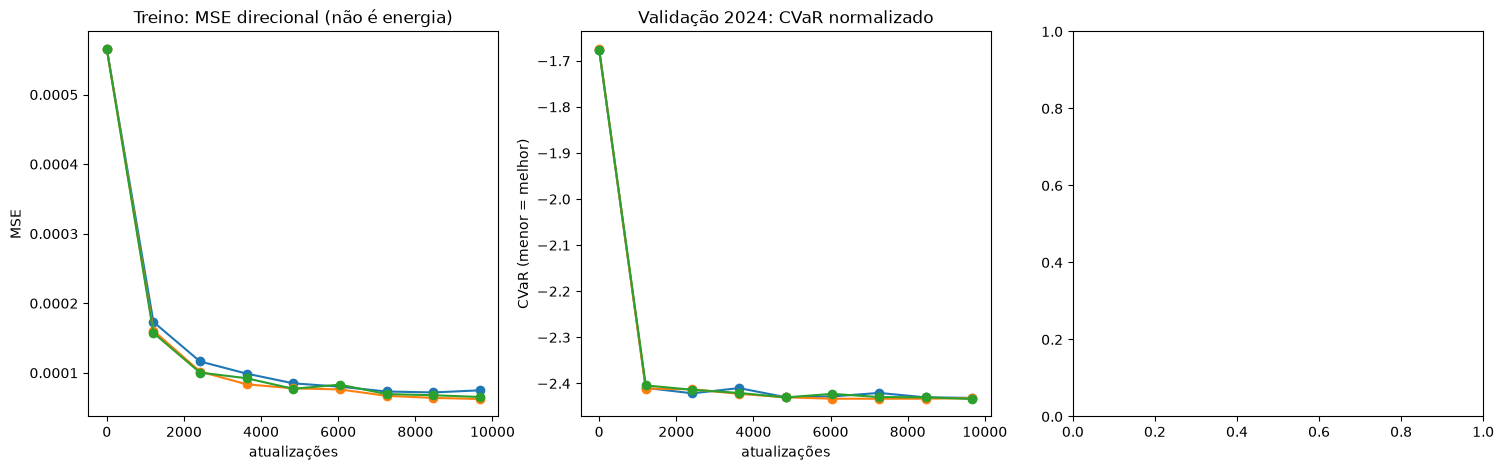

In [59]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
for arm,g in history.groupby('arm'):
    gg=g.groupby('update',as_index=False).agg(loss=('train_mse','mean'),val=('val_cvar','mean'))
    axes[0].plot(gg['update'],gg['loss'],marker='o',label=arm)
    axes[1].plot(gg['update'],gg['val'],marker='o',label=arm)
axes[0].set(title='Treino: MSE direcional (não é energia)',xlabel='atualizações',ylabel='MSE')
axes[1].set(title='Validação 2024: CVaR normalizado',xlabel='atualizações',ylabel='CVaR (menor = melhor)')

### 24.2 — Adicionar os testes retrospectivos e mostrar o gráfico

O eixo horizontal do teste distingue anos e grupos de ativos. Guardamos a figura com **o mesmo nome de arquivo original**. A figura executada no G5.38 foi preservada logo abaixo.

In [60]:
view=results.groupby(['year','asset_group','method'],as_index=False).agg(regret=('regret_context','mean'))
for arm,g in view.groupby('method'):
    if arm in ARMS:
        axes[2].plot(g.year.astype(str)+' '+g.asset_group,g.regret,marker='o',label=arm)
axes[2].set(title='Teste retrospectivo: distância até ótimo clássico',ylabel='regret (menor = melhor)')
axes[2].tick_params(axis='x',rotation=35)
for ax in axes: ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT/'g538_treino_validacao_teste.png',dpi=160,bbox_inches='tight')
plt.show()

### 24.3 — Comparações pareadas, mantendo as mesmas instâncias

Em vez de comparar médias de amostras diferentes, construímos uma tabela em que cada linha contém a mesma instância financeira, semente e os resultados de todos os métodos.

In [61]:
wide=results.pivot_table(index=['seed','instance','year','asset_group','spec'],
                         columns='method',values='context_energy').reset_index()
swap_e=results.groupby(['seed','instance']).classical_1swap_energy.first().reindex(
    pd.MultiIndex.from_frame(wide[['seed','instance']])).to_numpy()
for arm in ARMS:
    wide[f'gain_dicke_{arm}']=wide['DICKE']-wide[arm]
    wide[f'win_swap_{arm}']=wide[arm]<swap_e-1e-12
wide.to_csv(OUT/'test_paired_comparison.csv',index=False)

### 24.4 — Resumir ganhos médios por ano e grupo

Ganho positivo sobre Dicke é bom. `win_1swap` é fração de casos em que a arquitetura superou estritamente o método clássico com contexto. A tabela executada originalmente permanece abaixo.

In [62]:
report=wide.groupby(['year','asset_group'],as_index=False).agg(
    **{f'gain_dicke_{a}':(f'gain_dicke_{a}','mean') for a in ARMS},
    **{f'win_1swap_{a}':(f'win_swap_{a}','mean') for a in ARMS},n=('seed','size'))
report.to_csv(OUT/'g538_summary.csv',index=False)
print(report.round(5).to_string(index=False))

 year asset_group  gain_dicke_ENCODER_ONLY  gain_dicke_ENCODER_ONLY_MATCHED  gain_dicke_ENCODER_DECODER_CROSS  win_1swap_ENCODER_ONLY  win_1swap_ENCODER_ONLY_MATCHED  win_1swap_ENCODER_DECODER_CROSS   n
 2025     holdout                  0.08545                          0.08395                           0.08479                     0.0                             0.0                              0.0 640
 2025       train                  0.11468                          0.11306                           0.11226                     0.0                             0.0                              0.0 960
 2026     holdout                  0.07841                          0.07708                           0.07715                     0.0                             0.0                              0.0 480
 2026       train                  0.16666                          0.16514                           0.16542                     0.0                             0.0                       

## 25. Inspecionar um caso concreto: bitstring verdadeiro e probabilidades

Agora usamos o **vetor de estado ideal somente para análise**. Para 10C5 existem 252 carteiras, logo podemos calcular cada probabilidade exata $P_\phi(x)$.

**Acerto em um shot:** $p_\star=P_\phi(x_\star)$.

**Acerto em $B$ shots independentes:** $P(\text{acertar pelo menos uma vez})=1-(1-p_\star)^B$.

A probabilidade de cada bitstring é diferente da energia: o Transformer aprende a **redistribuir probabilidades**, e a função clássica decide quais bitstrings têm menor energia.

### 25.1 — Escolher uma instância 10C5 e enumerar bitstrings válidos

Selecionamos o primeiro problema 10C5 disponível; calculamos suas 252 energias e o índice de cada bitstring no vetor de estado do Qiskit.

In [63]:
from qiskit.quantum_info import Statevector
r=next((r for r in TEST if r['spec']==(10,5)),TEST[0])
Xf=feasible_states(r['n'],r['k'])
Ef=energies_subset(Xf,r['mu'],r['Sigma'])
bitind=np.sum(Xf.astype(np.int64)*(1<<np.arange(r['n'])),axis=1).astype(int)
labels=[CIRCS[r['spec']].label(x) for x in Xf]
seed=SEEDS[0]

### 25.2 — Extrair a probabilidade exata de cada bitstring

Para cada arquitetura, carregamos o `BEST` da primeira semente e calculamos seu estado ideal. A probabilidade total das carteiras viáveis precisa somar 1. O ótimo clássico somente entra no cálculo da Hamming e na etiqueta de auditoria.

In [64]:
mass_records,p_records=[],[]
for arm in ('DICKE',)+ARMS:
    if arm=='DICKE':
        phi=CIRCS[r['spec']].phiD
    else:
        c=checkpoints[(checkpoints.seed==seed)&(checkpoints.arm==arm)&(checkpoints.policy=='BEST')]
        net=new_network(arm)
        net.load_state_dict(torch.load(OUT/c.iloc[0].filename,map_location='cpu',weights_only=True))
        phi=predict_phi(net,r)
    qc=CIRCS[r['spec']].circuit(phi)
    qc.remove_final_measurements(inplace=True)
    prob=(np.abs(np.asarray(Statevector.from_instruction(qc).data))**2)[bitind]
    assert abs(prob.sum()-1)<1e-8
    for i,x in enumerate(Xf):
        ham=int(np.sum(x!=r['oracle_x']))
        mass_records.append(dict(arm=arm,hamming=ham,mass=float(prob[i])))
        p_records.append(dict(arm=arm,bitstring=labels[i],energy=float(Ef[i]),
                              probability=float(prob[i]),hamming=ham,
                              is_opt=int(np.array_equal(x,r['oracle_x']))))

### 25.3 — Massa de probabilidade por distância de Hamming

Hamming 0 = exatamente o ótimo; Hamming 2 = troca de um ativo; Hamming 4 = duas trocas. Barras comparam Dicke e as três redes. **A figura original foi mantida.**

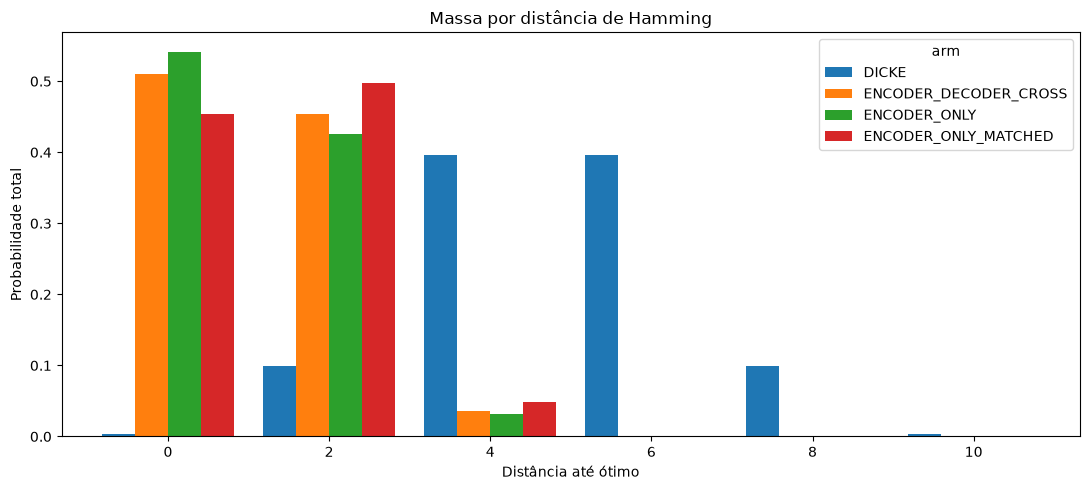

In [65]:
pd.DataFrame(p_records).to_csv(OUT/'exact_bitstring_distribution_showcase.csv',index=False)
massdf=pd.DataFrame(mass_records).groupby(['arm','hamming'],as_index=False).mass.sum()
pivot=massdf.pivot(index='hamming',columns='arm',values='mass').fillna(0)
fig,ax=plt.subplots(figsize=(11,5))
pivot.plot(kind='bar',ax=ax,width=.82)
ax.set(title='Massa por distância de Hamming',xlabel='Distância até ótimo',ylabel='Probabilidade total')
ax.tick_params(axis='x',rotation=0)
fig.tight_layout()
fig.savefig(OUT/'g538_hamming_agrupado.png',dpi=160)
plt.show()

### 25.4 — Tabela: quais bitstrings recebem maior probabilidade?

A tabela mostra as 15 carteiras mais prováveis no encoder-only original, com energia e Hamming. É a forma mais direta de conferir se a rede concentra massa no bitstring verdadeiro ou em soluções vizinhas.

In [66]:
cc=pd.DataFrame(p_records)
best=cc[cc.arm=='ENCODER_ONLY'].sort_values('probability',ascending=False).head(15)
display(best.round(6))

,arm,bitstring,energy,probability,hamming,is_opt
387,ENCODER_ONLY,0011001110,-1.784789,0.541752,0,1
255,ENCODER_ONLY,0010001111,-1.114026,0.123854,2,0
267,ENCODER_ONLY,0011000111,-1.161955,0.090159,2,0
391,ENCODER_ONLY,1010001110,-1.487036,0.034121,2,0
410,ENCODER_ONLY,1011000110,-1.520547,0.033008,2,0
317,ENCODER_ONLY,0011001101,-0.957785,0.031337,2,0
390,ENCODER_ONLY,0110001110,-1.493357,0.020654,2,0
409,ENCODER_ONLY,0111000110,-1.541747,0.019981,2,0
380,ENCODER_ONLY,0010011110,-1.259277,0.019454,2,0
465,ENCODER_ONLY,1011001100,-1.313216,0.016808,2,0


### 25.5 — Gráfico de probabilidade e energia em função do bitstring

Ordenamos as carteiras da menor para maior energia. As barras indicam probabilidade; a linha indica energia. Etiquetas identificam os 12 bitstrings mais prováveis e o ótimo. A figura executada foi preservada.

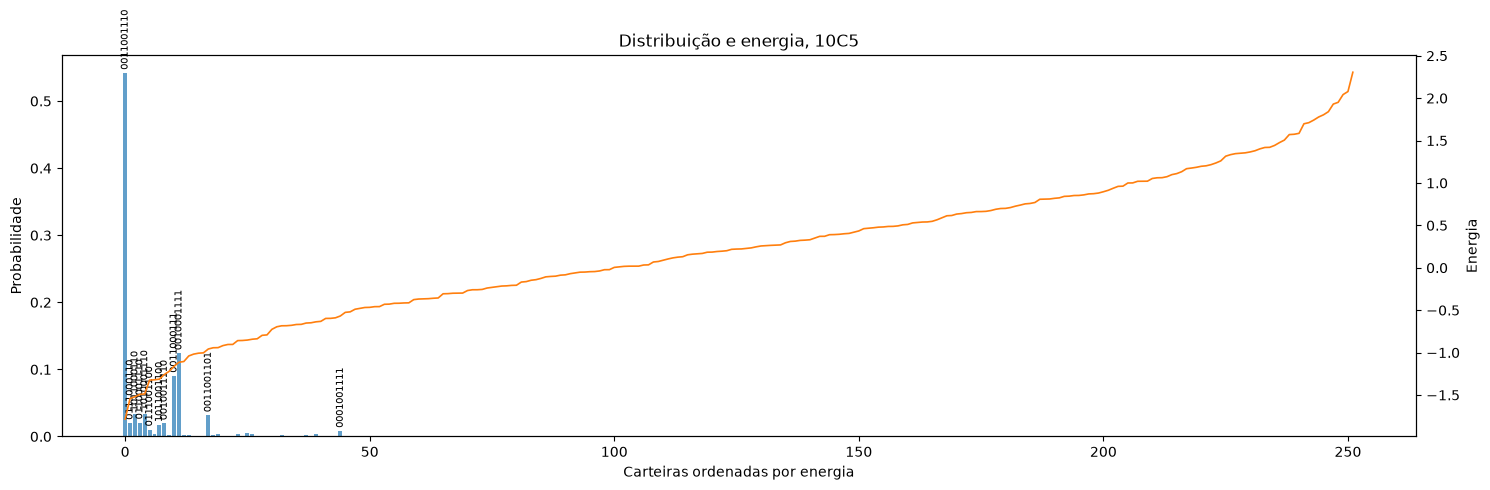

In [67]:
sub=cc[cc.arm=='ENCODER_ONLY'].sort_values('energy').reset_index(drop=True)
fig,ax=plt.subplots(figsize=(15,5))
ax.bar(np.arange(len(sub)),sub.probability,alpha=.7)
a2=ax.twinx()
a2.plot(np.arange(len(sub)),sub.energy,linewidth=1.2,color='tab:orange')
chosen=set(sub.nlargest(12,'probability').index.tolist())|set(sub.index[sub.is_opt==1])
for j in sorted(chosen):
    ax.annotate(sub.loc[j,'bitstring'],(j,float(sub.loc[j,'probability'])),
                rotation=90,textcoords='offset points',xytext=(0,4),ha='center',fontsize=7)
ax.set(title=f'Distribuição e energia, {r["n"]}C{r["k"]}',
       xlabel='Carteiras ordenadas por energia',ylabel='Probabilidade')
a2.set_ylabel('Energia')
fig.tight_layout()
fig.savefig(OUT/'g538_probabilidades_bitstrings_energia.png',dpi=160,bbox_inches='tight')
plt.show()

## 26. Interpretação científica dos resultados preservados

No G5.38 executado, o encoder-only original foi o melhor dos três modelos na avaliação retrospectiva. Os resultados mostram aprendizado de distribuições melhores que Dicke; **não demonstram vantagem quântica sobre 1-SWAP**. Nos 128 shots, 1-SWAP permaneceu competitivo ou superior.

**Limitações a mencionar na apresentação:**

- As 9.672 instâncias reutilizam ativos, janelas e datas; não são amostras financeiras independentes.
- `BEST` é escolhido apenas por CVaR em 2024, não pelos testes futuros.
- O gabarito clássico só existe na avaliação; não ensinamos $\theta_\star$ ao modelo.
- A comparação de 128 consultas não é uma comparação de tempo real ou custo físico em hardware quântico.
- O notebook usa Qiskit Aer MPS local: o circuito é simulado, não executado em processador quântico.

**Mensagem para o público:** *“Nosso algoritmo aprende a configuração de portas de um circuito de cardinalidade fixa a partir do Hamiltoniano, com um único forward. As medições amostram a distribuição produzida, e testamos a solução contra o ótimo clássico.”*

### 26.1 — Salvar o registro metodológico para reproduzir o trabalho

O manifesto inclui dados, sementes, número de shots, arquitetura, datas, critério do checkpoint e limitações. Removemos do registro apenas o antigo campo de piloto; nenhuma configuração científica foi modificada.

In [68]:
manifest_out=dict(experiment='G5.38',source='Dados reais e código G5.38',
    train='2024 train only',validation='2024 val only',
    tests='2025/2026 retrospectivos',seeds=list(SEEDS),arms=list(ARMS),
    parameter_counts=PARAMETERS,effective_parameter_counts=EFFECTIVE_PARAMS,
    train_pool=len(TRAIN),full_pool_passes=FULL_POOL_PASSES,
    updates_per_net=TRAIN_UPDATES,visits=visits.to_dict('records'),
    train_shots_per_net=TRAIN_SHOTS_TOTAL,validation_shots_per_net=VAL_SHOTS_TOTAL,
    common_context_samples=INPUT_SAMPLES,test_new_candidates=TEST_SHOTS,
    classical_oracle='Enumeração exata apenas nos testes',
    checkpoint_selection='CVaR 10% da validação 2024',
    objective='CVaR 10% igual em todas as arquiteturas',
    limitations=['Testes retrospectivos','Dependência entre janelas financeiras',
        'Comparação de avaliações não equivale a tempo de hardware'])
with open(OUT/'g538_manifest.json','w',encoding='utf8') as f:
    json.dump(manifest_out,f,ensure_ascii=False,indent=2)
print('Resultados na pasta:',OUT)

Resultados na pasta: /home/marlonmaxuel/Desktop/g538_didatico_reexecucao_2024
